# QALB beat classifier: data, results and confusion matrix

This notebook walks through the MIT-BIH data, the inter-patient split, the trained model and the held-out DS2 results. Run `python train.py` first so `reports/metrics.json` and the model exist.

In [1]:
import sys, json
sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from qalb_ml.config import CLASSES, DS1, DS2, FS, PRE, POST, REPORT_DIR
from qalb_ml.data import load_record, list_records
from qalb_ml.preprocess import preprocess_window
from qalb_ml.dataset import load_ds1, load_ds2
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Data
44 usable records remain after dropping the four paced ones (102, 104, 107, 217). Only lead MLII is used.

44 records; 22 in DS1, 22 in DS2


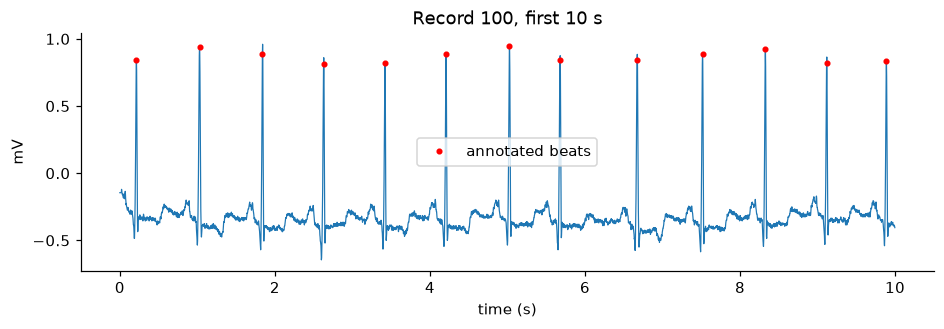

In [2]:
print(len(list_records()), 'records;', len(DS1), 'in DS1,', len(DS2), 'in DS2')
sig, fs, peaks, labels = load_record('100')
t = np.arange(10 * fs) / fs
plt.figure(figsize=(10, 2.8))
plt.plot(t, sig[:10 * fs], lw=0.8)
m = peaks < 10 * fs
plt.plot(peaks[m] / fs, sig[peaks[m]], 'r.', label='annotated beats')
plt.xlabel('time (s)'); plt.ylabel('mV'); plt.title('Record 100, first 10 s'); plt.legend(); plt.show()

## 2. Preprocessing
Band-pass 0.5-40 Hz plus baseline removal, then 0.25 s before and 0.4 s after each R peak.

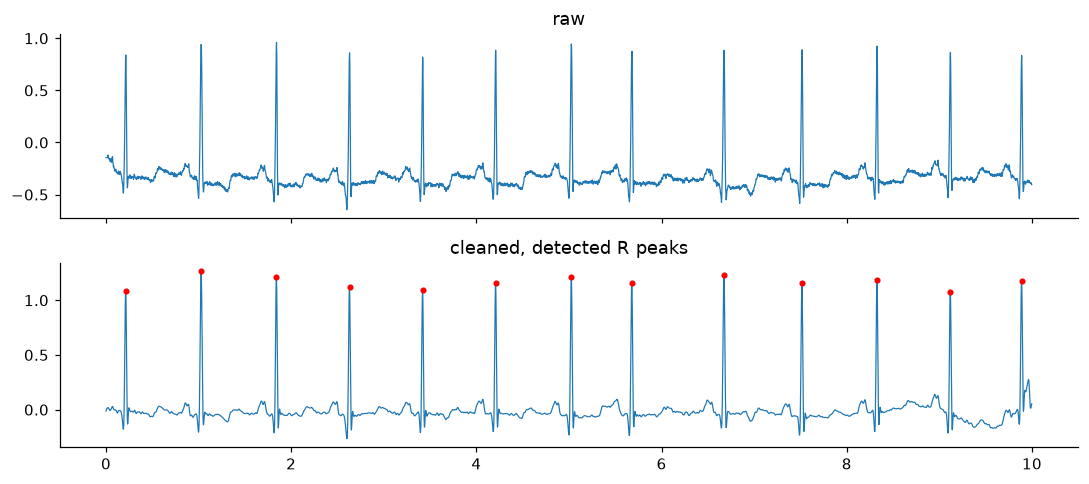

In [3]:
out = preprocess_window(sig[:10 * fs], fs)
fig, ax = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
ax[0].plot(t, sig[:10 * fs], lw=0.8); ax[0].set_title('raw')
ax[1].plot(t[:len(out['clean'])], out['clean'], lw=0.8)
ax[1].plot(out['peaks'] / FS, out['clean'][out['peaks']], 'r.'); ax[1].set_title('cleaned, detected R peaks')
plt.tight_layout(); plt.show()

## 3. Class balance and the inter-patient split
DS1 trains and DS2 tests. No patient appears in both.

In [4]:
X1, y1, g1 = load_ds1(); X2, y2, g2 = load_ds2()
import pandas as pd
print(pd.DataFrame({'DS1': np.bincount(y1, minlength=5), 'DS2': np.bincount(y2, minlength=5)}, index=CLASSES))
print('features per beat:', X1.shape[1])

     DS1    DS2
N  45849  44240
S    944   1837
V   3788   3220
F    414    388
Q      8      7
features per beat: 174


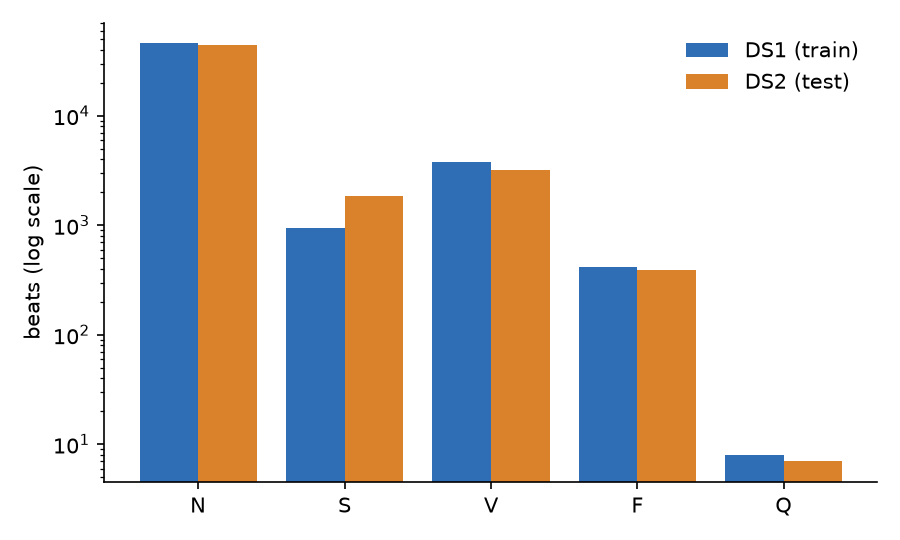

In [5]:
from IPython.display import Image
Image(str(REPORT_DIR / 'class_distribution.png'))

## 4. Beat shapes per class
Mean normalised beat per class in DS1 (the raw samples are the last block of features).

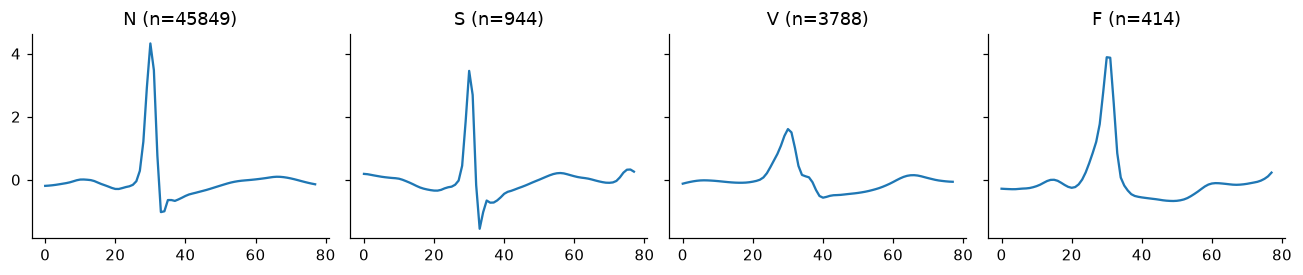

In [6]:
from qalb_ml.features import feature_dim, morphology_raw
n_raw = (PRE + POST + 2) // 3
fig, ax = plt.subplots(1, 4, figsize=(12, 2.6), sharey=True)
for k, c in enumerate(['N', 'S', 'V', 'F']):
    rows = X1[y1 == CLASSES.index(c)][:, -n_raw:]
    ax[k].plot(rows.mean(axis=0)); ax[k].set_title(f'{c} (n={len(rows)})')
plt.tight_layout(); plt.show()

## 5. Model comparison
Models are chosen with patient-grouped cross-validation on DS1 only. DS2 was scored once.

In [7]:
res = json.loads((REPORT_DIR / 'metrics.json').read_text())
cv = pd.DataFrame(res['cross_validation_ds1']).T
print('selected model:', res['selected_model'])
cv

selected model: gradient_boosting


,macro_f1_mean,macro_f1_std
logreg,0.421214,0.090203
random_forest,0.440920,0.071679
gradient_boosting,0.451222,0.109596
mlp,0.414421,0.052069


In [8]:
rows = []
for name, m in res['test_ds2'].items():
    rows.append({'model': name, 'accuracy': m['accuracy'], 'macro F1 (N,S,V,F)': m['macro_f1_scored'],
                 'V sensitivity': m['v_sensitivity'], 'S sensitivity': m['s_sensitivity']})
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,"macro F1 (N,S,V,F)",V sensitivity,S sensitivity
model,,,,
logreg,0.794,0.536,0.898,0.563
random_forest,0.943,0.479,0.905,0.024
gradient_boosting,0.835,0.483,0.965,0.185
mlp,0.826,0.410,0.909,0.106


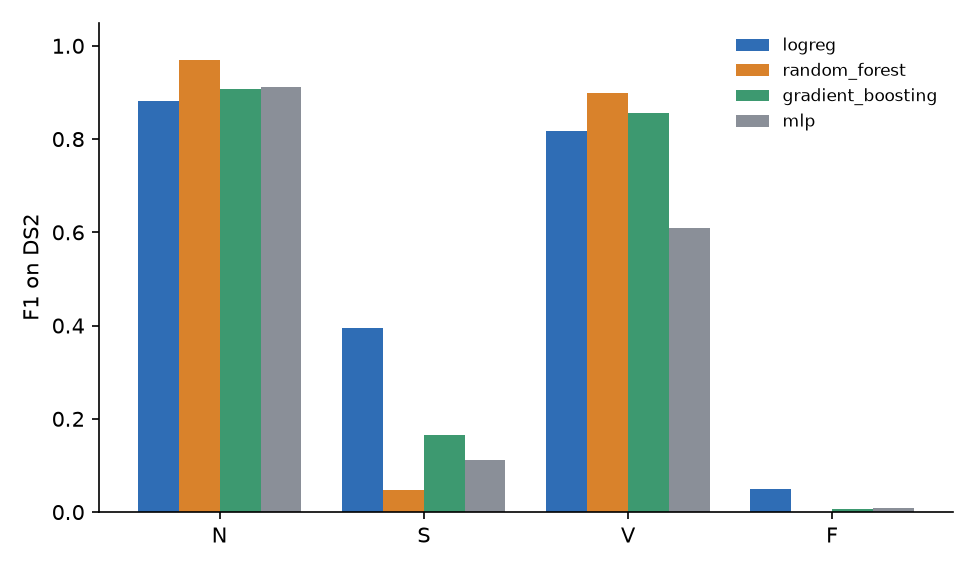

In [9]:
Image(str(REPORT_DIR / 'f1_by_class.png'))

## 6. Confusion matrix of the selected model on DS2

   precision  recall     f1  support
N      0.961   0.860  0.908  44240.0
S      0.148   0.185  0.164   1837.0
V      0.768   0.965  0.855   3220.0
F      0.003   0.034  0.006    388.0
Q      0.000   0.000  0.000      7.0


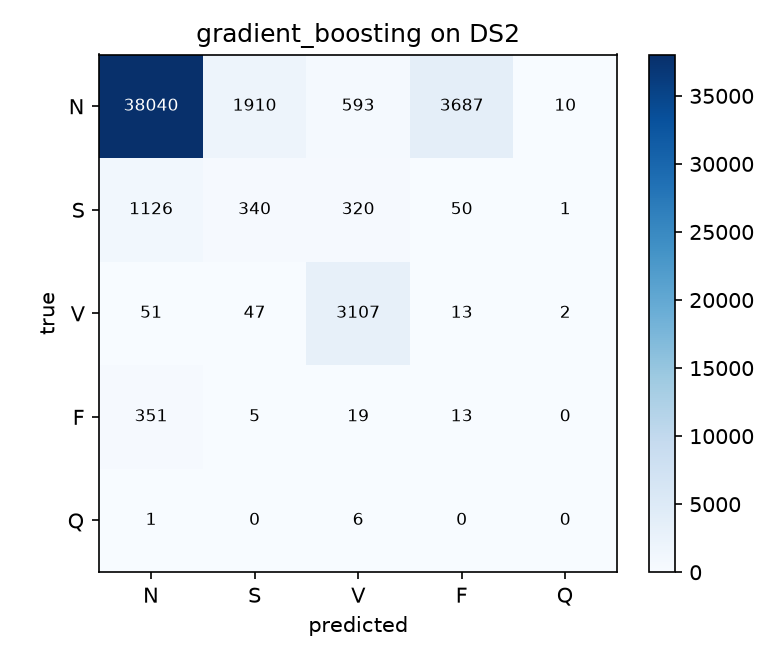

In [10]:
best = res['test_ds2'][res['selected_model']]
print(pd.DataFrame(best['per_class']).T.round(3))
Image(str(REPORT_DIR / 'confusion_best.png'))

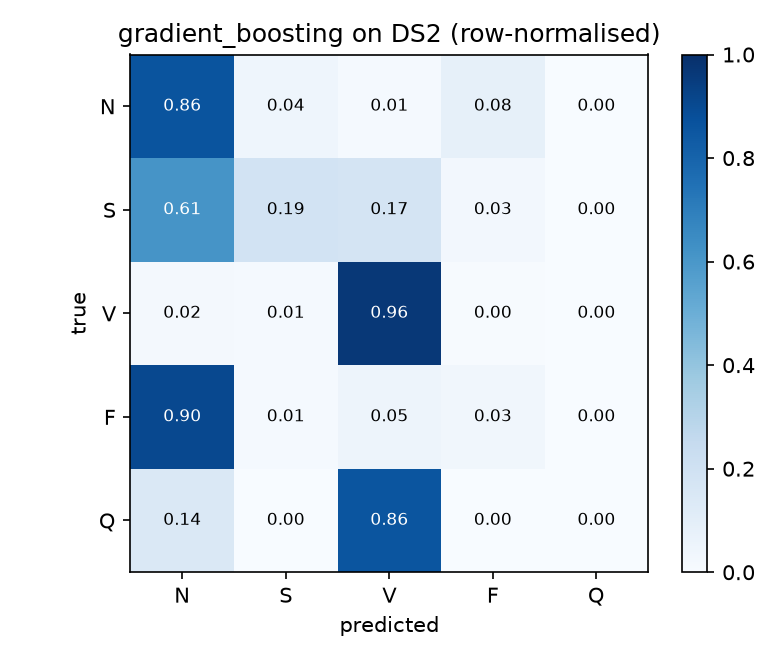

In [11]:
Image(str(REPORT_DIR / 'confusion_best_normalised.png'))

The Q class has only 8 training and 7 test beats once paced records are removed, so it is reported but excluded from the macro average. Most errors are S beats read as N and F beats read as N or V, the usual weak spots for inter-patient evaluation.

## 7. Improving the classifier
The baseline above is balanced gradient boosting on 174 features. Seven changes were tried one at a time. Every choice was made with patient-grouped cross-validation on DS1; DS2 was scored once at the end. Changes that did not help are kept in the story.

In [12]:
from qalb_ml.cv import N_FOLDS
EXP = REPORT_DIR / 'experiments'
exp = lambda n: json.loads((EXP / f'{n}.json').read_text())
def cv_table(d, keys):
    return pd.DataFrame({k: {'CV macro-F1': f"{d[k]['macro_f1_mean']:.3f} +/- {d[k]['macro_f1_std']:.3f}",
                              'S recall': round(d[k]['s_recall'], 3), 'V recall': round(d[k]['v_recall'], 3),
                              'F recall': round(d[k]['f_recall'], 3)} for k in keys}).T
print(N_FOLDS, 'patient-grouped folds on DS1')

4 patient-grouped folds on DS1


### Step 1: richer features
RR context, wavelet band descriptors and shape ratios were added to the 174 baseline features, alone and together.

In [13]:
s1 = exp('step1_features'); cv_table(s1, [k for k in s1 if isinstance(s1[k], dict)])

,CV macro-F1,S recall,V recall,F recall
v1 (baseline),0.451 +/- 0.110,0.321,0.913,0.002
v1 + RR context,0.445 +/- 0.112,0.268,0.911,0.002
v1 + wavelet bands,0.452 +/- 0.108,0.289,0.9,0.005
v1 + shape ratios,0.461 +/- 0.118,0.344,0.9,0.002
v2 (all),0.458 +/- 0.113,0.261,0.868,0.002


The gain is small and inside the fold-to-fold spread. Shape ratios help most, RR context alone does not help.

### Step 2: class imbalance
Weights, oversampling inside each training fold and focal-style weights.

In [14]:
s2 = exp('step2_imbalance'); cv_table(s2, [k for k in s2 if isinstance(s2[k], dict)])

,CV macro-F1,S recall,V recall,F recall
no weighting,0.462 +/- 0.095,0.153,0.853,0.0
balanced weights,0.458 +/- 0.113,0.261,0.868,0.002
sqrt-balanced weights,0.455 +/- 0.101,0.181,0.833,0.0
oversample to 25% of N,0.480 +/- 0.101,0.257,0.853,0.0
oversample to 50% of N,0.491 +/- 0.116,0.305,0.868,0.002
focal gamma=1,0.444 +/- 0.093,0.269,0.811,0.002
focal gamma=2,0.433 +/- 0.107,0.303,0.798,0.007


Oversampling to half the N count wins. Focal weighting hurts.

### Step 3: decision thresholds
Per-class scales were fitted on out-of-fold probabilities and checked with nested cross-validation.

In [15]:
s3 = exp('step3_thresholds'); cv_table(s3['variants'], list(s3['variants']))

,CV macro-F1,S recall,V recall,F recall
none (argmax),0.491 +/- 0.116,0.305,0.868,0.002
macro-F1,0.480 +/- 0.110,0.242,0.83,0.007
"macro-F1, S and F precision >= 0.2",0.491 +/- 0.116,0.305,0.868,0.002


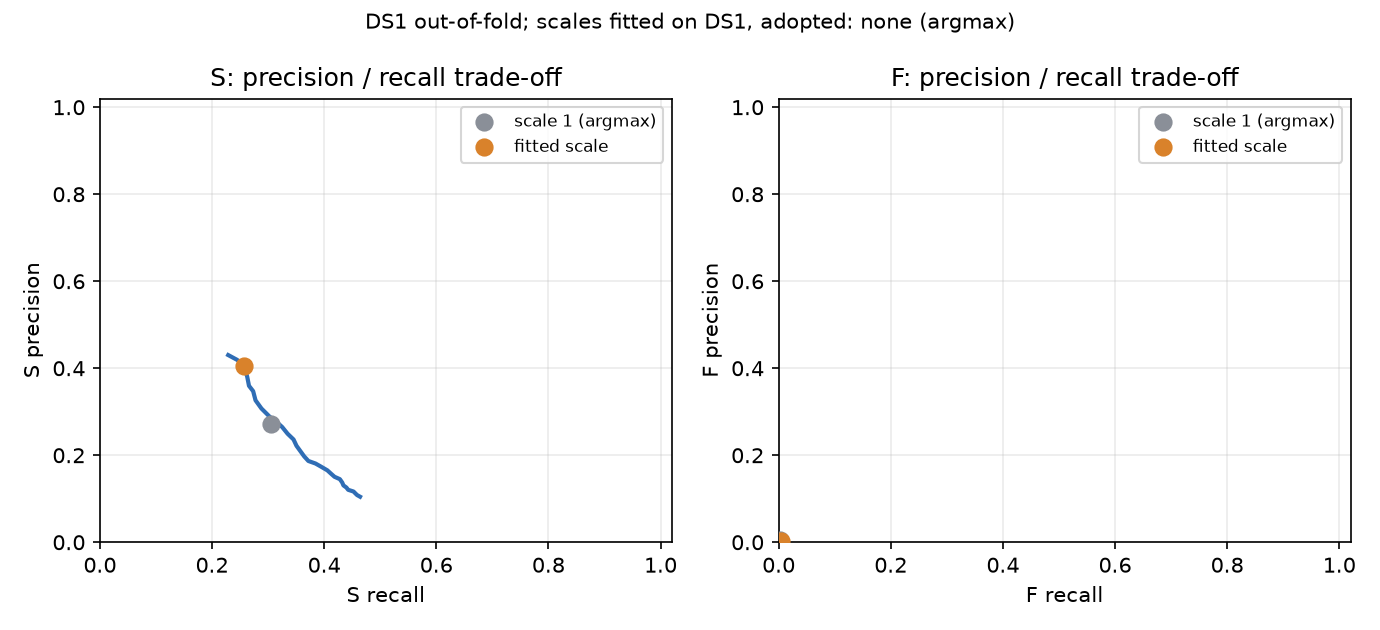

In [16]:
Image(str(REPORT_DIR / 'threshold_tradeoff.png'))

Scales fitted on all of DS1 do not transfer to held-out patients, so none were adopted. The figure shows what each operating point would cost.

### Step 4: tuned boosting
Ten random configurations with the same folds.

In [17]:
s4 = exp('step4_tuning')
pd.DataFrame([{**t['params'], 'CV macro-F1': round(t['macro_f1_mean'], 3)} for t in s4['trials']]).sort_values('CV macro-F1', ascending=False)

,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_iter,max_features,CV macro-F1
3,0.05,16,200,1.0,250,0.3,0.492
8,0.08,8,20,5.0,400,0.5,0.487
7,0.12,8,200,5.0,150,0.3,0.486
2,0.12,8,50,20.0,150,1.0,0.483
4,0.12,16,200,1.0,250,0.5,0.483
1,0.12,8,20,1.0,150,1.0,0.481
5,0.08,24,100,20.0,400,1.0,0.481
9,0.12,48,200,5.0,250,0.5,0.479
0,0.12,24,100,20.0,250,1.0,0.478
6,0.12,24,50,20.0,250,0.3,0.473


Best 0.492 against 0.491 for the defaults: no real gain, defaults kept.

### Steps 5 and 6: CNN and ensemble

In [18]:
s6 = exp('step6_ensemble')
cv_table(s6['stages'], ['boosting_tuned_argmax', 'cnn_argmax', 'ensemble_argmax'])

,CV macro-F1,S recall,V recall,F recall
boosting_tuned_argmax,0.491 +/- 0.116,0.305,0.868,0.002
cnn_argmax,0.448 +/- 0.045,0.352,0.841,0.0
ensemble_argmax,0.501 +/- 0.116,0.336,0.899,0.002


In [19]:
pd.Series(s6['weight_grid_scores']).round(3).rename('CV macro-F1 by weight on boosting').to_frame().T

,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
CV macro-F1 by weight on boosting,0.448,0.456,0.463,0.468,0.47,0.501,0.5,0.497,0.495,0.493,0.491


The CNN alone is weaker than boosting in cross-validation but errs differently; an even blend is the best configuration on DS1.

### Final result on DS2 (scored once)

In [20]:
print((REPORT_DIR / 'comparison.md').read_text())

| stage | CV macro-F1 (DS1) | DS2 macro-F1 | S recall | V recall | F recall | S prec | F prec | accuracy |
|---|---|---|---|---|---|---|---|---|
| baseline (v1 features, balanced boosting) | 0.451 +/- 0.110 | 0.483 | 0.185 | 0.965 | 0.034 | 0.15 | 0.00 | 0.835 |
| 1 richer features | 0.458 +/- 0.113 | 0.490 | 0.289 | 0.965 | 0.057 | 0.25 | 0.00 | 0.820 |
| 2 imbalance: oversample to 50% of N | 0.491 +/- 0.116 | 0.519 | 0.165 | 0.966 | 0.046 | 0.34 | 0.01 | 0.899 |
| 3 decision thresholds | 0.491 +/- 0.116 | 0.519 | 0.165 | 0.966 | 0.046 | 0.34 | 0.01 | 0.899 |
| 4 boosting search (default kept) + thresholds | 0.491 +/- 0.116 | 0.519 | 0.165 | 0.966 | 0.046 | 0.34 | 0.01 | 0.899 |
| 5 CNN alone | 0.448 +/- 0.045 | 0.560 | 0.366 | 0.964 | 0.023 | 0.42 | 0.00 | 0.898 |
| 6 ensemble + thresholds | 0.501 +/- 0.116 | 0.555 | 0.256 | 0.968 | 0.039 | 0.41 | 0.01 | 0.924 |



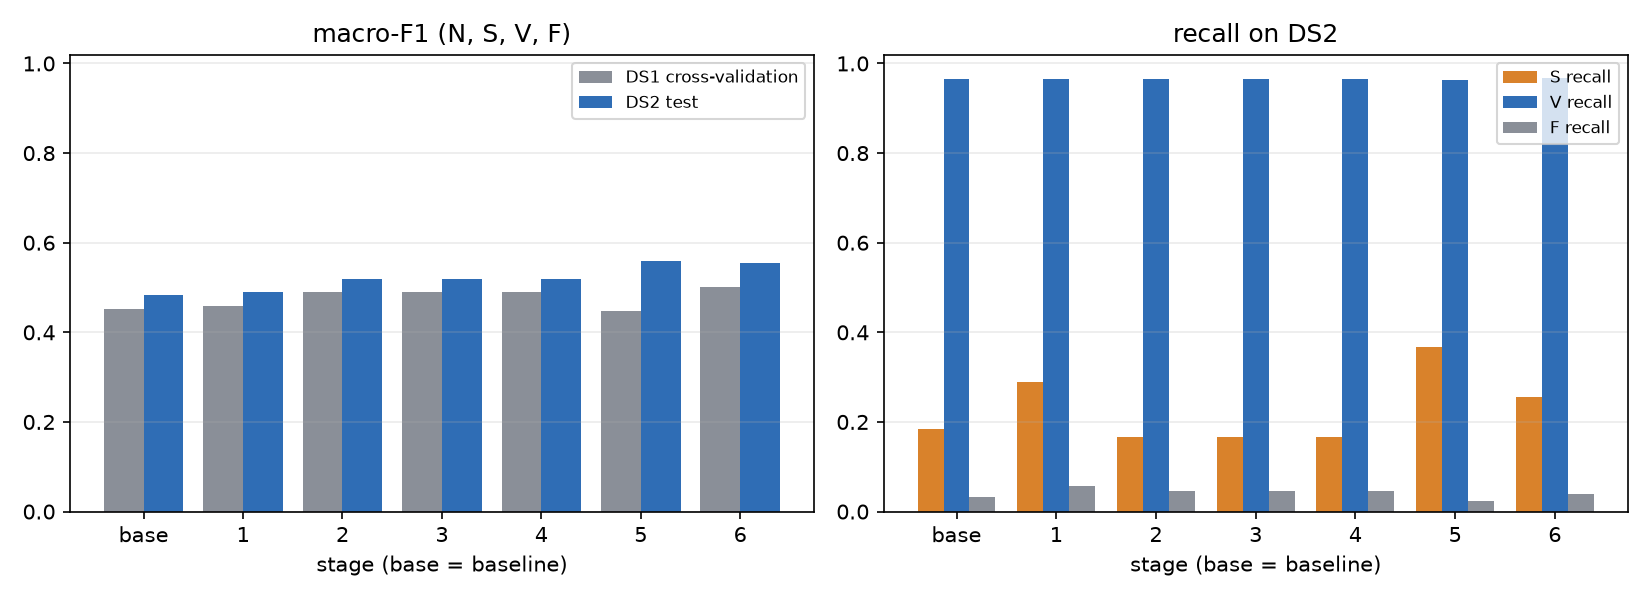

In [21]:
Image(str(REPORT_DIR / 'comparison_stages.png'))

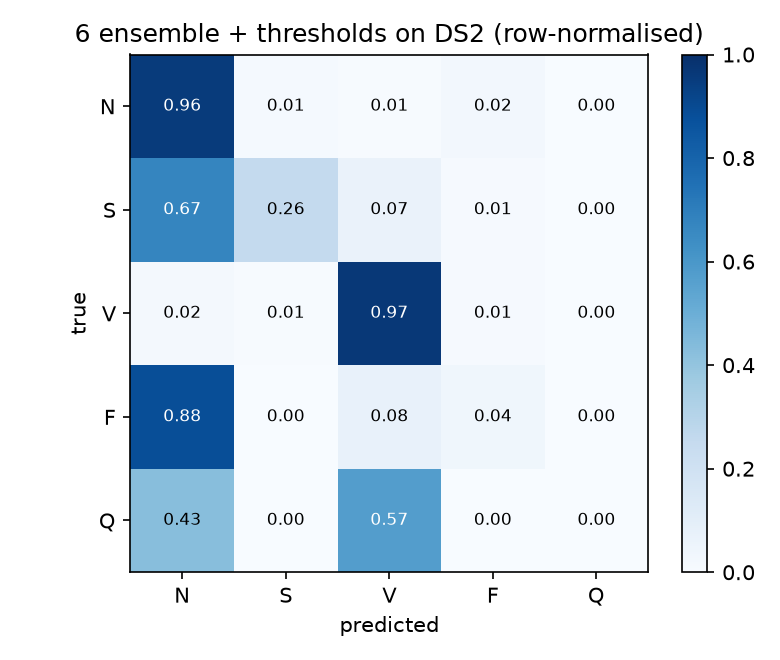

In [22]:
Image(str(REPORT_DIR / 'confusion_final_normalised.png'))

The final ensemble lifts macro-F1 from 0.483 to 0.555 and S precision from 0.15 to 0.41 while keeping V sensitivity near 0.97. S sensitivity improves only from 0.185 to 0.256, and fusion beats (F) are still essentially not recognised. On DS2 the CNN alone scored slightly higher (0.560) than the ensemble (0.555), but the ensemble was chosen on DS1 cross-validation before DS2 was opened and was not changed afterwards.

### Speed and size

In [23]:
print((REPORT_DIR / 'benchmark.md').read_text())

# Inference benchmark

Machine: Intel64 Family 6 Model 140 Stepping 1, GenuineIntel, Windows 10, Python 3.13.3, one process, CPU only. Latency is the median (and 95th percentile) of 10 runs after a warm-up call, on MIT-BIH record 100. Run `python benchmark.py` to reproduce on your machine.

| measurement | boosting_cnn_ensemble | gradient_boosting |
|---|---|---|
| first analysis after start (loads model, torch, CNN) | 2370 ms | 168 ms |
| per beat (10 s window divided by beats) | 3.20 ms | 2.83 ms |
| per 10 s window, median / p95 | 35 / 36 ms | 31 / 36 ms |
| per uploaded 30 s file, median / p95 | 71 / 75 ms | 72 / 82 ms |
| peak memory of a fresh process (resident) | 339 MB | 172 MB |

The second column, when present, is the torch-missing fallback (boosting model only), forced by disabling torch detection.

| model file | size |
|---|---|
| qalb_beat_classifier.joblib | 1.15 MB |
| qalb_beat_cnn.pt | 0.13 MB |
| total | 1.28 MB |



## 8. Alerts on a test record
The model and rule layer applied to 60 s of DS2 record 233, which has runs of ventricular beats.

In [24]:
sys.path.insert(0, '..')
from predict import predict_window
sig, fs, peaks, labels = load_record('233')
res_w = predict_window(sig[fs*300:fs*360], fs)
print(res_w['rhythm'])
for a in res_w['alerts']: print(a['severity'], a['type'], a['confidence'], a['message'])
print(res_w['disclaimer'])

{'n_beats': 97, 'class_counts': {'N': 63, 'S': 0, 'V': 31, 'F': 3, 'Q': 0}, 'mean_hr_bpm': 98.2, 'rr_mean_s': 0.611, 'rr_cv': 0.315, 'rr_jump_fraction': 0.705, 'rhythm': 'irregular'}
medium irregular_rhythm 1.0 Irregular rhythm: RR variation 32% with 70% large interval changes
high ventricular_run 0.921 Ventricular pattern: run of 5 ventricular beats (~63 bpm)
medium ventricular_couplet 0.797 Ventricular pattern: two consecutive ventricular beats
QALB is a research and monitoring prototype. It is not a medical device and must not be used for diagnosis or treatment decisions.


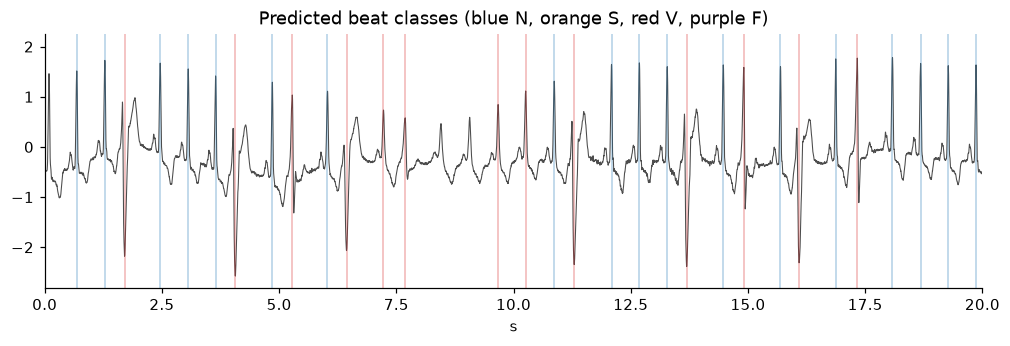

In [25]:
t = np.arange(len(sig[fs*300:fs*360])) / fs
plt.figure(figsize=(11, 3))
plt.plot(t, sig[fs*300:fs*360], lw=0.7, color='0.3')
colors = {'N': 'tab:blue', 'S': 'tab:orange', 'V': 'tab:red', 'F': 'tab:purple', 'Q': 'gray'}
for b in res_w['beats']:
    plt.axvline(b['time_s'], color=colors[b['class']], alpha=0.35, lw=1)
plt.title('Predicted beat classes (blue N, orange S, red V, purple F)'); plt.xlabel('s'); plt.xlim(0, 20); plt.show()